# Bike Sharing Demand Prediction
### Time Series Forecasting with a Transformer Built from Scratch

This project predicts hourly bike rental demand using the real Capital Bikeshare dataset (Washington, D.C., 2011-2012) - and does it with a **Transformer encoder built entirely from scratch**: no pretrained weights, no transfer learning. Every layer is randomly initialized and trained only on this dataset.

1. **Section 1 - Imports and Setup**
2. **Section 2 - Data Extraction and Verification**
3. **Section 3 - Exploratory Data Analysis**
4. **Section 4 - Feature Engineering**
5. **Section 5 - Building Sequences for the Transformer**
6. **Section 6 - Building a Transformer Encoder from Scratch**
7. **Section 7 - Training and Evaluation**
8. **Section 8 - Visualizing Predictions**
9. **Section 9 - Testing on Individual Time Windows**

**About the dataset:** 17,379 hourly records of bike rentals from Capital Bikeshare in Washington, D.C., spanning 2011-2012, along with the weather and calendar conditions at each hour (Fanaee-T & Gama, 2013).


## Why a Transformer for This?

- Bike demand at any given hour depends heavily on **recent history** - what happened in the last few hours (rush hour building up, a storm just passing) carries information that a single hour's weather reading alone does not.
- A **Transformer encoder** looks at a whole window of recent hours at once and uses **self-attention** to learn which of those past hours matter most for predicting the next one - rather than only looking at the single most recent hour, or treating every past hour as equally important.
- Unlike the pretrained models used in earlier projects (a locator finding objects, a classifier backbone), there is no equivalent "already trained on millions of examples" Transformer available for this specific demand-forecasting task - so this one is trained entirely from scratch, from randomly initialized weights.


## Section 1 - Imports and Setup


In [1]:
# PURPOSE OF THIS CELL
# This setup cell makes the notebook portable. It checks whether every required
# package is already installed and installs only the missing ones. This avoids
# reinstalling large packages, especially TensorFlow, on every notebook run.
#
# TEACHING NOTE
# `metadata.version()` checks package metadata without importing the package.
# `sys.executable` ensures pip installs into the same Python environment that is
# currently running this notebook. In a managed classroom environment, you may
# remove the installation block and install dependencies once from a terminal.

# Fast dependency check: reads each package's installed metadata instead of
# actually importing it - importing a library just to check "is it
# installed" is itself slow, especially for TensorFlow.
from importlib import metadata  # Imports package metadata utilities for dependency checks.
import subprocess  # Imports process tools used to run pip when a package is missing.
import sys  # Imports interpreter information so pip uses this notebook environment.

required_packages = ["requests", "pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "tensorflow"]  # Lists every external package required by the notebook.

missing = []  # Creates an empty list that will collect unavailable packages.
for package_name in required_packages:  # Checks every required package one at a time.
    try:  # Begins a protected operation that may raise an expected exception.
        metadata.version(package_name)  # Checks whether this package is installed without importing it.
    except metadata.PackageNotFoundError:  # Handles the case where the current package is not installed.
        missing.append(package_name)  # Adds the unavailable package to the installation list.

if missing:  # Runs installation only when at least one dependency is unavailable.
    print(f"Installing missing packages: {missing}")  # Displays progress, dimensions, metrics, or diagnostic information.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing)  # Installs all missing packages into the active Python environment.
    print("Done.")  # Displays progress, dimensions, metrics, or diagnostic information.
else:  # Handles the alternative condition.
    print("All required packages are already installed - nothing to do.")  # Displays progress, dimensions, metrics, or diagnostic information.


Installing missing packages: ['tensorflow']
Done.


In [2]:
# PURPOSE OF THIS CELL
# Import the numerical, data-processing, plotting, machine-learning, and deep-
# learning libraries used throughout the project. The printed environment check
# is useful when students run the same notebook on different computers.
#
# IMPORTANT
# A GPU can accelerate training, but this compact model is intentionally small
# enough to run on a CPU. Different TensorFlow versions or hardware may produce
# slightly different metrics even when the overall conclusions are unchanged.

import numpy as np  # array math
import pandas as pd  # loading and manipulating the tabular dataset
import matplotlib.pyplot as plt  # plotting time series and evaluation charts
import seaborn as sns  # nicer statistical plots
import tensorflow as tf  # builds and trains the Transformer, entirely from scratch

from sklearn.preprocessing import StandardScaler  # scales continuous features
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # regression evaluation metrics

sns.set_style("whitegrid")  # Applies a consistent white-grid style to Seaborn plots.
print("TensorFlow version:", tf.__version__)  # Displays progress, dimensions, metrics, or diagnostic information.
print("GPU available:", tf.config.list_physical_devices('GPU'))  # Displays progress, dimensions, metrics, or diagnostic information.


TensorFlow version: 2.21.0
GPU available: []


## Section 2 - Data Extraction and Verification

We download the real dataset as a CSV, trying two independent mirrors in case one is temporarily unavailable, and verify the result against the dataset's known, published shape before doing anything else with it.


### Dataset Access and Citation

This notebook uses the **Bike Sharing** dataset from the UCI Machine Learning Repository. It contains hourly and daily rental counts from the Capital Bikeshare system in Washington, D.C., for 2011-2012, together with weather and seasonal variables.

- Official dataset page: https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset
- Official dataset ZIP: https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip
- Direct `hour.csv` mirror used by the notebook: https://raw.githubusercontent.com/muditp19/UCI_Bike-sharing-dataset/master/hour.csv
- Backup `hour.csv` mirror: https://raw.githubusercontent.com/rachelleperez/Bike-Sharing/master/hour.csv
- Capital Bikeshare system data page: https://capitalbikeshare.com/system-data

**Dataset citation:** Fanaee-T, H. and Gama, J. (2014). *Event labeling combining ensemble detectors and background knowledge*. Progress in Artificial Intelligence, 2, 113-127. Dataset available through the UCI Machine Learning Repository.

The official UCI page is the authoritative source. The raw GitHub links are convenience mirrors that allow the notebook to load `hour.csv` directly.


In [3]:
# PURPOSE OF THIS CELL
# Download `hour.csv`, the hourly version of the UCI Bike Sharing dataset. Two
# mirrors are tried in order so a temporary failure of one host does not stop the
# lesson. The official UCI page is retained as the authoritative manual fallback.
#
# RELIABILITY NOTE
# `raise_for_status()` converts HTTP errors into exceptions, `timeout=30` prevents
# an endless wait, and the loop reports each failed source before trying the next.
# The following cell validates the returned file before it is trusted.

DATA_URLS = [  # Starts the ordered list of automatic dataset download sources.
    "https://raw.githubusercontent.com/muditp19/UCI_Bike-sharing-dataset/master/hour.csv",  # Provides a direct CSV mirror that the loader can try.
    "https://raw.githubusercontent.com/rachelleperez/Bike-Sharing/master/hour.csv",  # Provides a direct CSV mirror that the loader can try.
]  # Ends the current multi-line list.


def load_dataset():  # Defines a reusable function for downloading the dataset safely.
    """Tries each mirror in turn and returns the first one that loads
    successfully as a proper CSV."""
    import requests  # Imports the HTTP client used to download the CSV file.
    import io  # Imports in-memory text streams for converting downloaded text into a CSV source.

    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36"}  # Sets a browser-like user agent for reliable HTTP access.

    for url in DATA_URLS:  # Attempts each dataset mirror in the listed order.
        try:  # Begins a protected operation that may raise an expected exception.
            response = requests.get(url, headers=headers, timeout=30)  # Downloads the current URL with a timeout to prevent indefinite waiting.
            response.raise_for_status()  # Raises an exception if the server returns an HTTP error.
            df = pd.read_csv(io.StringIO(response.text))  # Parses the downloaded CSV text into a pandas DataFrame.
            print(f"Loaded successfully from: {url}")  # Displays progress, dimensions, metrics, or diagnostic information.
            return df  # Returns the successfully loaded DataFrame to the caller.
        except Exception as e:  # Catches a download or parsing failure so the next mirror can be tried.
            print(f"Failed to load from {url}: {e}")  # Displays progress, dimensions, metrics, or diagnostic information.

    return None  # Signals that every automatic dataset source failed.


df = load_dataset()  # Calls the loader and stores the resulting dataset.

if df is None:  # Checks whether automatic downloading failed completely.
    print()  # Displays progress, dimensions, metrics, or diagnostic information.
    print("MANUAL FALLBACK: download the dataset yourself from UCI:")  # Displays progress, dimensions, metrics, or diagnostic information.
    print("  https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset")  # Displays progress, dimensions, metrics, or diagnostic information.
    print('Then place "hour.csv" in the same folder as this notebook and load it with:')  # Displays progress, dimensions, metrics, or diagnostic information.
    print('  df = pd.read_csv("hour.csv")')  # Displays progress, dimensions, metrics, or diagnostic information.
    raise RuntimeError("Could not load the dataset automatically - see manual fallback above.")  # Stops execution because valid training data is unavailable.


Loaded successfully from: https://raw.githubusercontent.com/muditp19/UCI_Bike-sharing-dataset/master/hour.csv


In [4]:
# PURPOSE OF THIS CELL
# Validate the downloaded data before analysis. Shape, missing-value count, and
# column names act as simple integrity checks and help detect an HTML error page,
# an incomplete file, or a different dataset accidentally saved as `hour.csv`.
#
# `assert` deliberately stops execution when a requirement is not satisfied.
# This is safer than allowing unsuitable data to flow silently into the model.

# Verification step: confirm the data matches the dataset's known, published
# shape and structure before doing anything else with it.
print("Shape:", df.shape)  # Displays progress, dimensions, metrics, or diagnostic information.
assert df.shape == (17379, 17), f"Expected 17,379 rows and 17 columns, got {df.shape}"  # Confirms that the file has the published number of rows and columns.

print("Missing values:", df.isnull().sum().sum())  # Displays progress, dimensions, metrics, or diagnostic information.
assert df.isnull().sum().sum() == 0, "Expected no missing values in this dataset"  # Stops execution if the dataset unexpectedly contains missing values.

expected_columns = {  # Starts the set of column names expected in the official dataset.
    "instant", "dteday", "season", "yr", "mnth", "hr", "holiday", "weekday",  # Supplies the next value or argument in this multi-line statement.
    "workingday", "weathersit", "temp", "atemp", "hum", "windspeed",  # Supplies the next value or argument in this multi-line statement.
    "casual", "registered", "cnt",  # Supplies the next value or argument in this multi-line statement.
}  # Ends the current multi-line set or dictionary.
assert set(df.columns) == expected_columns, "Column names don't match the expected dataset"  # Verifies that the loaded schema exactly matches the expected schema.

print()  # Displays progress, dimensions, metrics, or diagnostic information.
print("Verification passed - this is the real, complete dataset.")  # Displays progress, dimensions, metrics, or diagnostic information.
df.head()  # Displays the first five rows for a quick visual inspection.


Shape: (17379, 17)
Missing values: 0

Verification passed - this is the real, complete dataset.


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## Section 3 - Exploratory Data Analysis


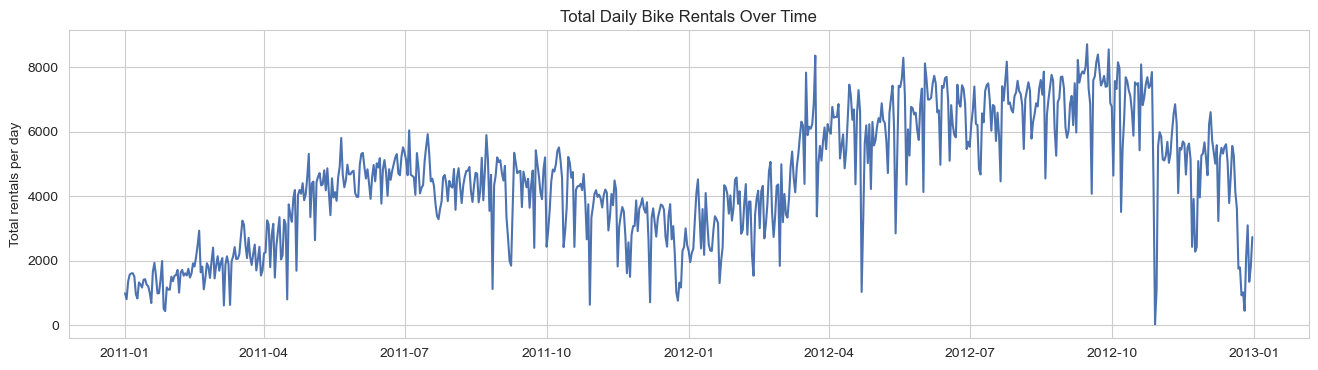

In [5]:
# PURPOSE OF THIS CELL
# Convert the date text into pandas datetime values, aggregate hourly rentals into
# daily totals, and inspect the long-term demand trend across 2011 and 2012.
# Aggregation makes the broad growth and seasonal pattern easier to see than a
# dense plot containing all 17,379 hourly observations.

df["dteday"] = pd.to_datetime(df["dteday"])  # parse the date column properly for time-based plotting

# Overall demand over the full two-year period.
plt.figure(figsize=(16, 4))  # Creates a new plot with the specified display size.
daily_totals = df.groupby("dteday")["cnt"].sum()  # Aggregates all hourly rentals into one total for each date.
plt.plot(daily_totals.index, daily_totals.values, color="#4C72B0")  # Draws a line showing the selected actual or predicted values.
plt.title("Total Daily Bike Rentals Over Time")  # Adds a descriptive title to the current chart.
plt.ylabel("Total rentals per day")  # Labels the vertical axis.
plt.show()  # Renders the completed chart in the notebook.


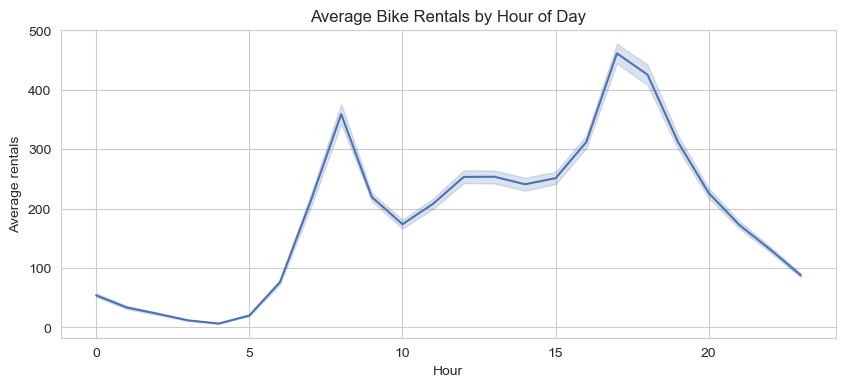

In [6]:
# PURPOSE OF THIS CELL
# Estimate average demand for each hour of the day. The 95% confidence interval
# summarizes uncertainty around the mean and the line commonly reveals morning
# and evening commuting peaks. This is descriptive EDA, not model evaluation.

# Demand by hour of day - the classic commuter double-peak pattern.
plt.figure(figsize=(10, 4))  # Creates a new plot with the specified display size.
sns.lineplot(x="hr", y="cnt", data=df, color="#4C72B0", errorbar=("ci", 95))  # Plots mean hourly demand with its uncertainty interval.
plt.title("Average Bike Rentals by Hour of Day")  # Adds a descriptive title to the current chart.
plt.xlabel("Hour")  # Labels the horizontal axis.
plt.ylabel("Average rentals")  # Labels the vertical axis.
plt.show()  # Renders the completed chart in the notebook.


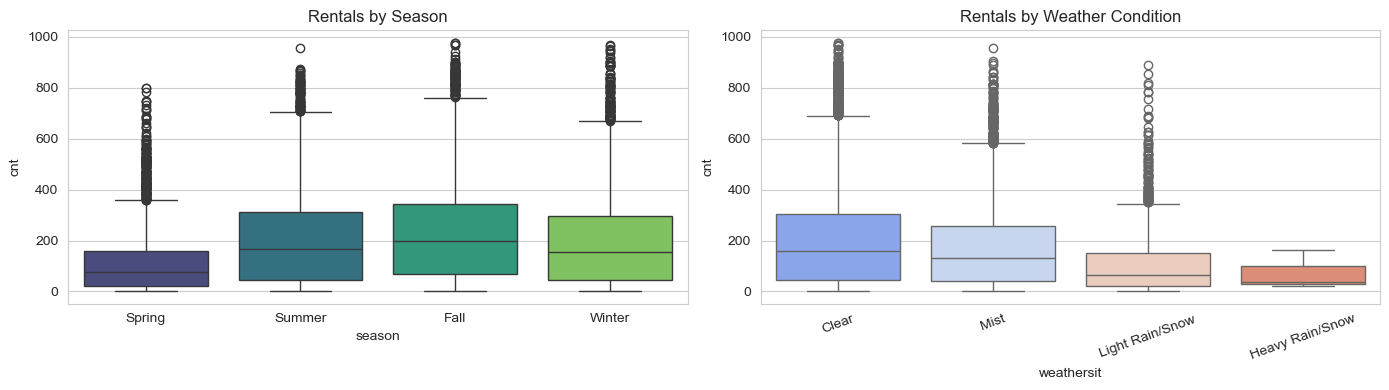

In [7]:
# PURPOSE OF THIS CELL
# Compare the complete distribution of bike demand across seasons and weather
# categories. A box plot shows the median, interquartile range, and possible
# outliers, so it communicates more than a chart of category means alone.
# Numeric category codes are mapped to readable labels only for presentation.

# Demand by season, and the effect of weather conditions.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))  # Creates two side-by-side axes for categorical comparisons.

season_labels = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}  # Maps numeric season codes to readable category names.
sns.boxplot(x=df["season"].map(season_labels), y=df["cnt"], hue=df["season"].map(season_labels),  # Draws a box plot to compare demand distributions across categories.
            palette="viridis", legend=False, ax=axes[0])  # Chooses the color palette and assigns the plot to the selected axis.
axes[0].set_title("Rentals by Season")  # Formats the selected subplot.

weather_labels = {1: "Clear", 2: "Mist", 3: "Light Rain/Snow", 4: "Heavy Rain/Snow"}  # Maps numeric weather codes to readable category names.
sns.boxplot(x=df["weathersit"].map(weather_labels), y=df["cnt"], hue=df["weathersit"].map(weather_labels),  # Draws a box plot to compare demand distributions across categories.
            palette="coolwarm", legend=False, ax=axes[1])  # Chooses the color palette and assigns the plot to the selected axis.
axes[1].set_title("Rentals by Weather Condition")  # Formats the selected subplot.
axes[1].tick_params(axis="x", rotation=20)  # Formats the selected subplot.

plt.tight_layout()  # Adjusts spacing so plot elements do not overlap.
plt.show()  # Renders the completed chart in the notebook.


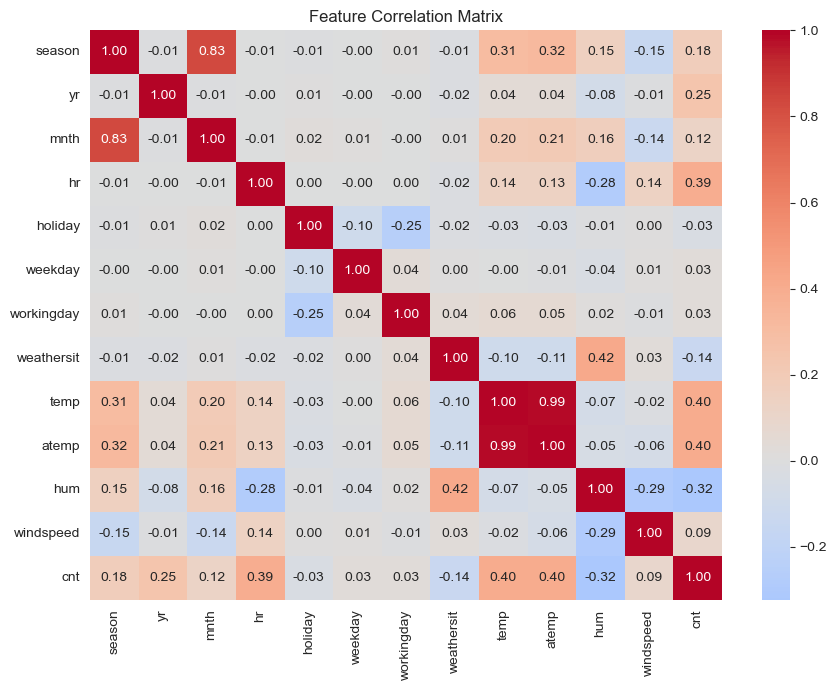

In [8]:
# PURPOSE OF THIS CELL
# Measure pairwise linear correlations among numeric variables. Values near +1
# indicate strong positive linear association, values near -1 indicate strong
# negative association, and values near 0 indicate weak linear association.
# Correlation does not establish causation and may miss nonlinear relationships.

# Correlation between the numeric features and the target.
plt.figure(figsize=(9, 7))  # Creates a new plot with the specified display size.
numeric_cols = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",  # Selects numeric variables for correlation analysis.
                 "weathersit", "temp", "atemp", "hum", "windspeed", "cnt"]  # Executes this step in the current data-processing or modeling workflow.
corr = df[numeric_cols].corr()  # Calculates the pairwise Pearson correlation matrix.
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)  # Visualizes correlations with annotated values and a centered color scale.
plt.title("Feature Correlation Matrix")  # Adds a descriptive title to the current chart.
plt.tight_layout()  # Adjusts spacing so plot elements do not overlap.
plt.show()  # Renders the completed chart in the notebook.


## Section 4 - Feature Engineering

A few important decisions here:

- **`casual` and `registered` are dropped entirely.** `cnt = casual + registered` exactly - using either as an input feature would let the model "predict" the answer from a piece of the answer itself. This is a textbook case of data leakage, and it's worth stopping on explicitly.
- **Cyclical encoding for periodic features.** Hour 23 and hour 0 are one hour apart, not 23 apart - encoding `hr` as a single number tells the model the opposite. We convert `hr`, `mnth`, and `weekday` into sine/cosine pairs so their natural cyclical structure is represented correctly.
- **One-hot encoding for `season` and `weathersit`**, since they're categories without a meaningful numeric order.
- **`temp`, `atemp`, `hum`, `windspeed` are already normalized to [0, 1]** by the dataset's original creators - no further scaling needed for those.


In [9]:
# PURPOSE OF THIS CELL
# Transform raw calendar and category fields into representations that are easier
# for a neural network to learn from while preventing target leakage.
#
# WHY SINE AND COSINE
# Clock and calendar variables wrap around: hour 23 is close to hour 0. Two cyclic
# coordinates preserve this circular relationship, unlike the raw integers.
#
# WHY ONE-HOT ENCODING
# Season and weather codes are labels, not quantities. One-hot columns prevent the
# model from assuming, for example, that weather code 4 is four times code 1.
#
# LEAKAGE WARNING
# `cnt` is exactly `casual + registered`; using either component would reveal the
# target. Both are therefore removed before the forecasting model is trained.

def cyclical_encode(df, col, max_val):  # Defines a helper that converts one periodic feature into sine and cosine.
    """Turns a periodic integer column into two columns (sin, cos) that
    correctly represent its circular structure."""
    df[col + "_sin"] = np.sin(2 * np.pi * df[col] / max_val)  # Creates the sine coordinate of the periodic feature.
    df[col + "_cos"] = np.cos(2 * np.pi * df[col] / max_val)  # Creates the cosine coordinate of the periodic feature.
    return df  # Returns the successfully loaded DataFrame to the caller.


features_df = df.copy()  # Copies the dataset so original data remain unchanged.
features_df = cyclical_encode(features_df, "hr", 24)  # Applies cyclical encoding to this calendar feature.
features_df = cyclical_encode(features_df, "mnth", 12)  # Applies cyclical encoding to this calendar feature.
features_df = cyclical_encode(features_df, "weekday", 7)  # Applies cyclical encoding to this calendar feature.

features_df = pd.get_dummies(features_df, columns=["season", "weathersit"], prefix=["season", "weather"])  # One-hot encodes nominal season and weather categories.

# Drop the leaky columns, the raw periodic columns we've now cyclically encoded,
# and columns that carry no predictive information (instant is just a row index).
drop_cols = ["instant", "dteday", "casual", "registered", "hr", "mnth", "weekday"]  # Lists identifiers, leakage fields, and replaced raw calendar columns.
features_df = features_df.drop(columns=drop_cols)  # Removes columns that must not enter the model.

print("Final feature columns:", list(features_df.columns))  # Displays progress, dimensions, metrics, or diagnostic information.
print("Shape:", features_df.shape)  # Displays progress, dimensions, metrics, or diagnostic information.


Final feature columns: ['yr', 'holiday', 'workingday', 'temp', 'atemp', 'hum', 'windspeed', 'cnt', 'hr_sin', 'hr_cos', 'mnth_sin', 'mnth_cos', 'weekday_sin', 'weekday_cos', 'season_1', 'season_2', 'season_3', 'season_4', 'weather_1', 'weather_2', 'weather_3', 'weather_4']
Shape: (17379, 22)


## Section 5 - Building Sequences for the Transformer

The Transformer doesn't see one hour at a time - it sees a **window of the past `WINDOW_SIZE` hours** and predicts the bike count for the hour right after that window. This is what lets self-attention find which recent hours matter most.

**Important: the train/test split must be chronological, not random.** Randomly shuffling time series data before splitting would let the model train on data from *after* the point it's being tested on - a real forecasting model never has access to the future. We use the first ~80% of the timeline for training and the last ~20% for testing.


In [10]:
# PURPOSE OF THIS CELL
# Define the forecasting horizon and divide the timeline into past training data
# and later test data. A 24-hour input window gives the Transformer one complete
# daily cycle before it predicts demand for the immediately following hour.
#
# TIME-SERIES RULE
# Never randomly shuffle before this split. A chronological split simulates real
# deployment: the model learns from the past and is evaluated on unseen future
# observations. The test set remains untouched until final evaluation.

WINDOW_SIZE = 24  # use the past 24 hours to predict the next hour's demand

feature_columns = [c for c in features_df.columns if c != "cnt"]  # Selects every model input column while excluding the target.
target_column = "cnt"  # Stores the name of the demand variable to predict.

# Chronological split - the LAST 20% of the timeline is held out for testing,
# never used in training or in fitting the scaler below.
split_index = int(len(features_df) * 0.8)  # Calculates the boundary after the first 80 percent of observations.
train_df = features_df.iloc[:split_index].reset_index(drop=True)  # Creates the earlier chronological training portion.
test_df = features_df.iloc[split_index:].reset_index(drop=True)  # Creates the later untouched chronological test portion.

print(f"Training rows: {len(train_df)} | Test rows: {len(test_df)}")  # Displays progress, dimensions, metrics, or diagnostic information.
print(f"Training period ends at row {split_index} of {len(features_df)} (~80%)")  # Displays progress, dimensions, metrics, or diagnostic information.


Training rows: 13903 | Test rows: 3476
Training period ends at row 13903 of 17379 (~80%)


In [11]:
# PURPOSE OF THIS CELL
# Standardize continuous inputs and the regression target so optimization is more
# stable. StandardScaler transforms each value using (value - training mean) /
# training standard deviation. Binary and one-hot columns do not need scaling.
#
# LEAKAGE PREVENTION
# Both scalers are fitted only on the training period. The saved training means
# and standard deviations are then applied unchanged to the future test period.

# Scale continuous features - fit on the TRAINING portion only, then apply
# that same transformation to the test portion. Fitting on the test set too
# would leak information about the future into preprocessing.
continuous_cols = ["temp", "atemp", "hum", "windspeed"]  # Lists continuous weather measurements that require standardization.

scaler = StandardScaler()  # Creates the input-feature standardization object.
train_df[continuous_cols] = scaler.fit_transform(train_df[continuous_cols])  # Learns scaling parameters from training inputs and transforms them.
test_df[continuous_cols] = scaler.transform(test_df[continuous_cols])  # Applies the training-derived scaling parameters to future test inputs.

# The target itself is also scaled - neural networks generally train more
# stably on normalized targets than on raw counts ranging into the hundreds.
target_scaler = StandardScaler()  # Creates a separate scaler for the regression target.
train_df[[target_column]] = target_scaler.fit_transform(train_df[[target_column]])  # Fits target scaling only on the training period.
test_df[[target_column]] = target_scaler.transform(test_df[[target_column]])  # Transforms test targets using training-only target statistics.

print("Scaling complete.")  # Displays progress, dimensions, metrics, or diagnostic information.


Scaling complete.


In [12]:
# PURPOSE OF THIS CELL
# Convert the flat hourly table into supervised learning examples. Each X sample
# contains 24 consecutive rows of features; its y value is the bike count in the
# next row. The window moves forward by one hour to create the next example.
#
# SHAPE GUIDE
# X has shape (number of examples, 24 hours, number of features). This three-
# dimensional structure is the sequence format expected by the Transformer.

def create_sequences(data, feature_cols, target_col, window_size):  # Defines the sliding-window conversion from rows to sequences.
    """Slides a window of `window_size` rows across the data, pairing each
    window with the target value of the row immediately after it."""
    X, y = [], []  # Creates containers for input windows and next-hour targets.
    feature_values = data[feature_cols].values.astype(np.float32)  # Converts feature columns to efficient float32 NumPy values.
    target_values = data[target_col].values.astype(np.float32)  # Converts target values to float32 for TensorFlow.

    for i in range(len(data) - window_size):  # Moves a 24-hour window across all valid starting positions.
        X.append(feature_values[i : i + window_size])  # past `window_size` hours of features
        y.append(target_values[i + window_size])  # the very next hour's count

    return np.array(X), np.array(y)  # Returns model-ready input and target arrays.


X_train, y_train = create_sequences(train_df, feature_columns, target_column, WINDOW_SIZE)  # Builds training windows and their next-hour labels.
X_test, y_test = create_sequences(test_df, feature_columns, target_column, WINDOW_SIZE)  # Builds test windows and their next-hour labels.

print("X_train shape:", X_train.shape, "(examples, window_size, num_features)")  # Displays progress, dimensions, metrics, or diagnostic information.
print("y_train shape:", y_train.shape)  # Displays progress, dimensions, metrics, or diagnostic information.
print("X_test shape:", X_test.shape)  # Displays progress, dimensions, metrics, or diagnostic information.
print("Number of input features per hour:", len(feature_columns))  # Displays progress, dimensions, metrics, or diagnostic information.


X_train shape: (13879, 24, 21) (examples, window_size, num_features)
y_train shape: (13879,)
X_test shape: (3452, 24, 21)
Number of input features per hour: 21


## Section 6 - Building a Transformer Encoder from Scratch

No pretrained weights anywhere in this model - every layer below starts from random initialization and learns entirely from this dataset.

- **Positional encoding**: self-attention has no built-in sense of order, so we add a fixed sinusoidal signal that tells the model where in the window each hour falls.
- **Multi-head self-attention**: lets every hour in the window "look at" every other hour and learn which ones matter most for the prediction.
- **Feed-forward network + residual connections + layer normalization**: the standard Transformer encoder block, applied after the attention step.
- **Global average pooling + a small regression head**: collapses the whole processed sequence down to a single predicted count.


In [13]:
# PURPOSE OF THIS CELL
# Build the complete Transformer regressor from randomly initialized Keras layers.
# No pretrained network or pretrained weights are loaded.
#
# MODEL FLOW
# 1. Project each hourly feature vector to `d_model` dimensions.
# 2. Add fixed sinusoidal positions so hour order is available to attention.
# 3. Apply stacked encoder blocks: self-attention, residual connections, layer
#    normalization, and a position-wise feed-forward network.
# 4. Pool the 24 encoded hours and map them to one continuous demand prediction.
#
# DIMENSION NOTE
# `d_model` must be divisible by `num_heads` because the representation is split
# evenly across attention heads. The final Dense(1) has no activation because this
# is regression; negative outputs are clipped only after inverse transformation.

def positional_encoding(window_size, d_model):  # Defines fixed sinusoidal positions for the sequence.
    """Fixed (non-trainable) sinusoidal positions - the classic Transformer
    positional encoding, computed once from scratch, not learned."""
    positions = np.arange(window_size)[:, np.newaxis]  # Creates one row index for every hour in the input window.
    dims = np.arange(d_model)[np.newaxis, :]  # Creates one index for every model representation dimension.
    angle_rates = 1 / np.power(10000, (2 * (dims // 2)) / np.float32(d_model))  # Calculates dimension-specific sinusoidal frequencies.
    angles = positions * angle_rates  # Combines positions and frequencies into encoding angles.

    pos_encoding = np.zeros((window_size, d_model))  # Initializes the positional encoding matrix.
    pos_encoding[:, 0::2] = np.sin(angles[:, 0::2])  # even dimensions get sine
    pos_encoding[:, 1::2] = np.cos(angles[:, 1::2])  # odd dimensions get cosine

    return tf.cast(pos_encoding[np.newaxis, ...], dtype=tf.float32)  # shape (1, window_size, d_model)


def transformer_encoder_block(inputs, d_model, num_heads, ff_dim, dropout_rate):  # Defines one reusable Transformer encoder block.
    """One Transformer encoder block: self-attention, then a feed-forward
    network, each wrapped in a residual connection and layer normalization."""
    attention_output = tf.keras.layers.MultiHeadAttention(  # Creates multi-head self-attention for relationships across hours.
        num_heads=num_heads, key_dim=d_model // num_heads  # Configures the number of attention heads and each head dimension.
    )(inputs, inputs)  # self-attention: the sequence attends to itself
    attention_output = tf.keras.layers.Dropout(dropout_rate)(attention_output)  # Regularizes the attention output during training.
    out1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)(inputs + attention_output)  # residual connection

    ffn_output = tf.keras.layers.Dense(ff_dim, activation="relu")(out1)  # Expands each position through the nonlinear feed-forward layer.
    ffn_output = tf.keras.layers.Dense(d_model)(ffn_output)  # Projects the feed-forward output back to the model dimension.
    ffn_output = tf.keras.layers.Dropout(dropout_rate)(ffn_output)  # Regularizes the feed-forward output during training.
    out2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)(out1 + ffn_output)  # residual connection

    return out2  # Returns the encoded sequence from this Transformer block.


def build_transformer_model(window_size, num_features, d_model=64, num_heads=4,  # Defines the complete next-hour demand regression model.
                             ff_dim=128, num_blocks=2, dropout_rate=0.1):  # Continues the model function parameters for depth and regularization.
    inputs = tf.keras.layers.Input(shape=(window_size, num_features))  # Declares a sequence input with 24 time steps and all features.

    x = tf.keras.layers.Dense(d_model)(inputs)  # project raw features up to the model's working dimension
    x = x + positional_encoding(window_size, d_model)  # inject positional information

    for _ in range(num_blocks):  # stack multiple encoder blocks for a deeper model
        x = transformer_encoder_block(x, d_model, num_heads, ff_dim, dropout_rate)  # Passes the sequence through one Transformer encoder block.

    x = tf.keras.layers.GlobalAveragePooling1D()(x)  # collapse the sequence dimension
    x = tf.keras.layers.Dense(64, activation="relu")(x)  # Learns a nonlinear representation for final regression.
    x = tf.keras.layers.Dropout(dropout_rate)(x)  # Adds final regularization before the prediction layer.
    outputs = tf.keras.layers.Dense(1)(x)  # a single regression output: predicted (scaled) count

    model = tf.keras.Model(inputs=inputs, outputs=outputs)  # Connects the declared inputs and outputs into a Keras model.
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])  # Configures Adam optimization, MSE loss, and MAE monitoring.
    return model  # Returns the compiled Transformer model.


bike_transformer = build_transformer_model(  # Creates the Transformer using the prepared input dimensions.
    window_size=WINDOW_SIZE, num_features=len(feature_columns)  # Supplies the 24-hour window and number of engineered features.
)  # Closes the current multi-line function call.
bike_transformer.summary()  # Displays layer shapes and trainable parameter counts.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 24, 21)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 24, 64)    │      1,408 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 24, 64)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 24, 64)    │     16,640 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 24, 64)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 24, 64)    │          0 │ add[0][0],        │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 24, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 24, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 24, 64)    │      8,256 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 24, 64)    │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 24, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 24, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 24, 64)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 24, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 64)    │        128 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 24, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 24, 64)    │      8,256 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 24, 64)    │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 24, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_5[0][0] 

 Total params: 72,577 (283.50 KB)

 Trainable params: 72,577 (283.50 KB)

 Non-trainable params: 0 (0.00 B)

## Section 7 - Training and Evaluation

We use early stopping to halt training automatically once validation loss stops improving, and keep the best epoch's weights.


In [21]:
# PURPOSE OF THIS CELL
# Train the model while monitoring loss on a validation slice taken from the
# training data. Early stopping limits unnecessary epochs and automatically
# restores the parameters from the epoch with the lowest validation loss.
#
# REPRODUCIBILITY NOTE
# Neural-network initialization and mini-batch optimization are stochastic. Exact
# numbers can vary between runs and hardware. For formal experiments, set seeds,
# repeat training several times, and report the mean and standard deviation.

early_stopping = tf.keras.callbacks.EarlyStopping(  # Creates validation-based early stopping.
    monitor="val_loss", patience=8, restore_best_weights=True  # Monitors validation loss, waits eight epochs, and restores the best weights.
)  # Closes the current multi-line function call.

history = bike_transformer.fit(  # Starts model training and saves epoch-level history.
    X_train, y_train,  # Supplies the training sequences and targets.
    validation_split=0.1,  # a slice of the (already chronological) training data, held out for monitoring during training
    epochs=60,  # Sets the maximum number of training passes.
    batch_size=64,  # Sets the number of sequences processed per gradient update.
    callbacks=[early_stopping],  # Activates early stopping during training.
    verbose=1,  # Enables epoch-by-epoch training progress output.
)  # Closes the current multi-line function call.


Epoch 1/60
196/196 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0744 - mae: 0.1906 - val_loss: 0.2410 - val_mae: 0.3386
Epoch 2/60
196/196 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - loss: 0.0675 - mae: 0.1840 - val_loss: 0.1366 - val_mae: 0.2572
Epoch 3/60
196/196 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.0662 - mae: 0.1813 - val_loss: 0.1350 - val_mae: 0.2488
Epoch 4/60
196/196 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - loss: 0.0620 - mae: 0.1755 - val_loss: 0.3126 - val_mae: 0.4272
Epoch 5/60
196/196 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - loss: 0.0614 - mae: 0.1733 - val_loss: 0.1876 - val_mae: 0.2928
Epoch 6/60
196/196 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0591 - mae: 0.1711 - val_loss: 0.1844 - val_mae: 0.2980
Epoch 7/60
196/196 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.0553 - mae: 0.1659 - val_loss: 0.1562 - val_mae: 0.2694
Epoch 8/60
196/196 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0549 - mae: 0.1644 - val_loss: 0.1586 - val_mae: 0.2637
Epoch 9/60
196/196 ━━━━━━━━━━━━━━━━━━━━ 10s 3

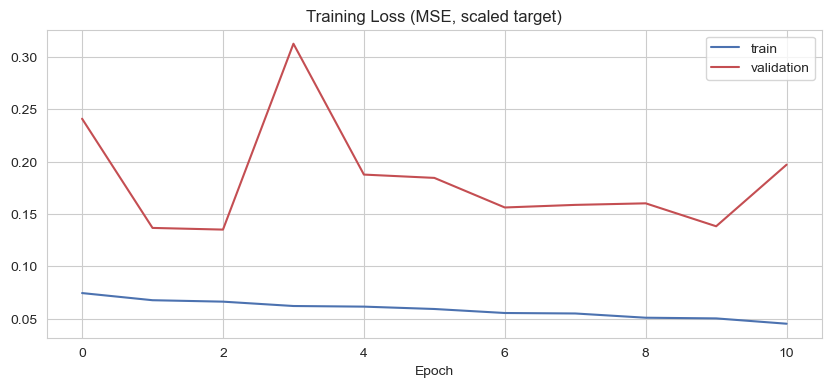

In [22]:
# PURPOSE OF THIS CELL
# Plot training and validation mean squared error across epochs. A falling training
# curve shows learning. If validation loss rises while training loss keeps falling,
# the gap is evidence of overfitting. The best epoch is restored by early stopping.

plt.figure(figsize=(10, 4))  # Creates a new plot with the specified display size.
plt.plot(history.history["loss"], label="train", color="#4C72B0")  # Draws a line showing the selected actual or predicted values.
plt.plot(history.history["val_loss"], label="validation", color="#C44E52")  # Draws a line showing the selected actual or predicted values.
plt.title("Training Loss (MSE, scaled target)")  # Adds a descriptive title to the current chart.
plt.xlabel("Epoch")  # Labels the horizontal axis.
plt.legend()  # Displays labels that identify the plotted series.
plt.show()  # Renders the completed chart in the notebook.


In [23]:
# PURPOSE OF THIS CELL
# Produce forecasts for the untouched chronological test set, undo target scaling,
# enforce the physical lower bound of zero rentals, and calculate three regression
# metrics in the original unit of bikes.
#
# METRIC INTERPRETATION
# MAE is the average absolute error. RMSE penalizes large errors more strongly.
# R2 is the fraction of target variance explained relative to predicting the test
# mean; higher is better, but it should always be interpreted with MAE and RMSE.

# Predict on the held-out test set, then convert predictions back to real
# bike counts (undo the target scaling from Section 5) before evaluating -
# error metrics in actual bike counts are far more interpretable than in
# scaled units.
y_pred_scaled = bike_transformer.predict(X_test, verbose=0).flatten()  # Generates scaled forecasts for every held-out test sequence.

y_test_actual = target_scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()  # Restores true test targets to bike-count units.
y_pred_actual = target_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()  # Restores predicted targets to bike-count units.
y_pred_actual = np.clip(y_pred_actual, 0, None)  # bike counts can never be negative

mae = mean_absolute_error(y_test_actual, y_pred_actual)  # Calculates average absolute error in bike counts.
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))  # Calculates root mean squared error, which emphasizes larger mistakes.
r2 = r2_score(y_test_actual, y_pred_actual)  # Calculates the proportion of test-target variance explained.

print(f"MAE:  {mae:.2f} bikes")  # Displays progress, dimensions, metrics, or diagnostic information.
print(f"RMSE: {rmse:.2f} bikes")  # Displays progress, dimensions, metrics, or diagnostic information.
print(f"R2:   {r2:.4f}")  # Displays progress, dimensions, metrics, or diagnostic information.


MAE:  48.01 bikes
RMSE: 71.05 bikes
R2:   0.8959


## Section 8 - Visualizing Predictions


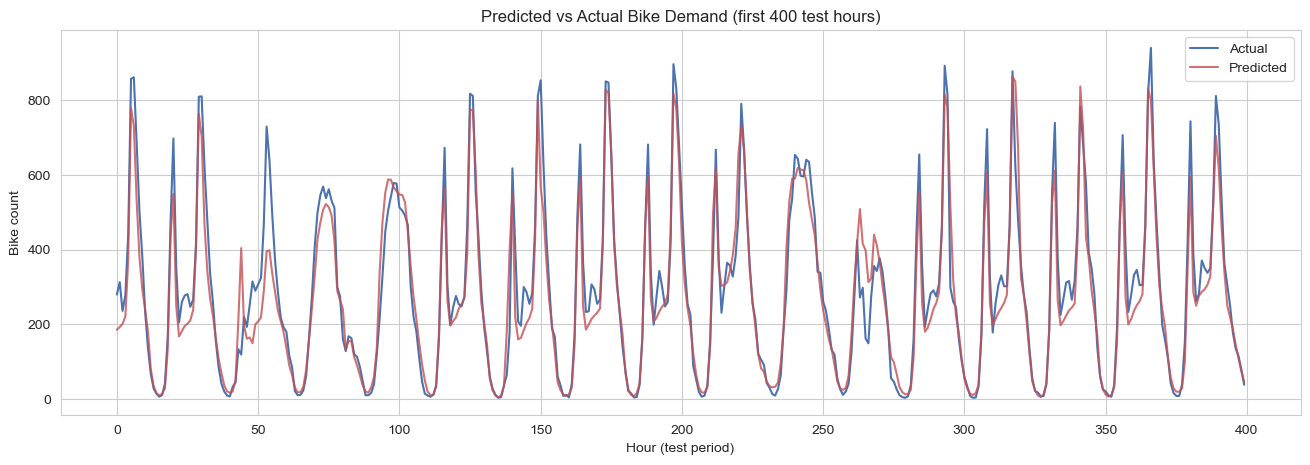

In [24]:
# PURPOSE OF THIS CELL
# Compare actual and predicted demand in chronological order for the first 400 test
# hours. This reveals whether the model follows local peaks, valleys, and timing.
# The display is limited to 400 hours only for readability; metrics use all tests.

plt.figure(figsize=(16, 5))  # Creates a new plot with the specified display size.
plt.plot(y_test_actual[:400], label="Actual", color="#4C72B0")  # Draws a line showing the selected actual or predicted values.
plt.plot(y_pred_actual[:400], label="Predicted", color="#C44E52", alpha=0.8)  # Draws a line showing the selected actual or predicted values.
plt.title("Predicted vs Actual Bike Demand (first 400 test hours)")  # Adds a descriptive title to the current chart.
plt.xlabel("Hour (test period)")  # Labels the horizontal axis.
plt.ylabel("Bike count")  # Labels the vertical axis.
plt.legend()  # Displays labels that identify the plotted series.
plt.show()  # Renders the completed chart in the notebook.


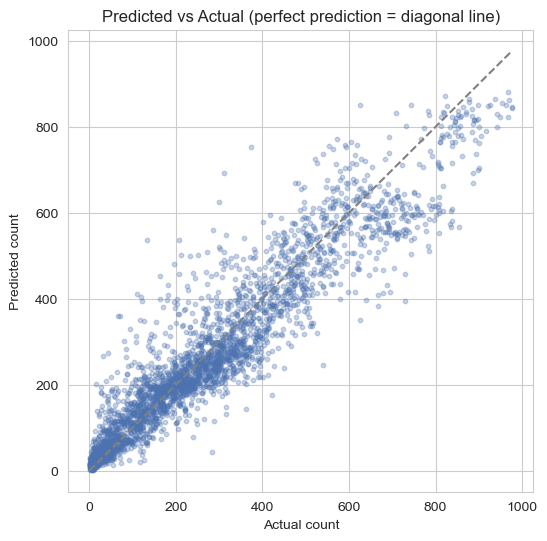

In [25]:
# PURPOSE OF THIS CELL
# Inspect calibration across the entire test set. Perfect predictions lie on the
# dashed y=x diagonal. Points above it are overpredictions; points below it are
# underpredictions. Increasing spread at high counts indicates peak-demand errors.

plt.figure(figsize=(6, 6))  # Creates a new plot with the specified display size.
plt.scatter(y_test_actual, y_pred_actual, alpha=0.3, color="#4C72B0", s=10)  # Plots every actual value against its corresponding prediction.
max_val = max(y_test_actual.max(), y_pred_actual.max())  # Finds a shared maximum for the perfect-prediction reference line.
plt.plot([0, max_val], [0, max_val], linestyle="--", color="gray")  # Draws a line showing the selected actual or predicted values.
plt.xlabel("Actual count")  # Labels the horizontal axis.
plt.ylabel("Predicted count")  # Labels the vertical axis.
plt.title("Predicted vs Actual (perfect prediction = diagonal line)")  # Adds a descriptive title to the current chart.
plt.show()  # Renders the completed chart in the notebook.


## Section 9 - Testing on Individual Time Windows

Pick any window from the test set and see the prediction next to the true value.


In [26]:
# PURPOSE OF THIS CELL
# Demonstrate inference on individual test windows. Slicing with `index:index+1`
# preserves the batch dimension required by Keras. Predictions and targets are
# inverse-transformed so the comparison is reported as an understandable bike count.
#
# INDEX RULE
# A valid index is between 0 and len(X_test)-1. These examples are demonstrations,
# not additional validation cases; all of them already belong to the test set.

def predict_single_window(index):  # Defines a helper for demonstrating one test-window forecast.
    window = X_test[index : index + 1]  # keep the batch dimension
    pred_scaled = bike_transformer.predict(window, verbose=0)[0][0]  # Predicts scaled demand for the selected sequence.
    pred_actual = max(0, target_scaler.inverse_transform([[pred_scaled]])[0][0])  # Converts the forecast to bike counts and enforces a zero lower bound.
    actual = target_scaler.inverse_transform([[y_test[index]]])[0][0]  # Converts the corresponding true target to bike counts.
    print(f"Window {index}: predicted {pred_actual:.0f} bikes, actual {actual:.0f} bikes")  # Displays progress, dimensions, metrics, or diagnostic information.


for i in [0, 50, 150, 300, 500]:  # Loops through five example positions in the test set.
    predict_single_window(i)  # Prints the forecast and actual value for this example.


Window 0: predicted 186 bikes, actual 280 bikes
Window 50: predicted 207 bikes, actual 307 bikes
Window 150: predicted 567 bikes, actual 854 bikes
Window 300: predicted 53 bikes, actual 59 bikes
Window 500: predicted 606 bikes, actual 808 bikes


## Wrap Up and Next Steps

**What we built, start to finish:**
- Downloaded and verified the real, two-year Capital Bikeshare hourly dataset
- Explored demand patterns by hour, season, and weather condition
- Engineered features correctly: dropped leaky columns (`casual`/`registered`), cyclically encoded periodic features, one-hot encoded categories
- Built sliding-window sequences with a strictly chronological train/test split - never letting the model see the future during training
- Built a **Transformer encoder entirely from scratch** - positional encoding, multi-head self-attention, feed-forward blocks, residual connections - with no pretrained weights anywhere
- Evaluated in real bike counts (MAE, RMSE, R²), not just scaled units

**Where to go from here:**
- Try different `WINDOW_SIZE` values (e.g. 48 or 72 hours) and see how much history actually helps.
- Add more Transformer blocks (`num_blocks`) or attention heads (`num_heads`) and compare against this smaller model - watch for overfitting given the dataset's modest size.
- Compare against a simpler baseline (e.g. a naive "same hour last week" forecast, or an LSTM) to see how much the self-attention mechanism is actually adding.
- Try forecasting multiple hours ahead at once instead of just the next single hour.


## Section 10 - Live Prediction

Run the cell below **after training the model**. Enter any test-window index from the displayed valid range. The cell immediately uses the corresponding 24-hour sequence to predict demand for the next hour and compares the prediction with the known actual value.

This is an interactive demonstration using held-out test sequences. For real deployment with newly collected data, the same feature engineering, column order, and training-fitted scalers must be applied to the latest 24 hourly records before prediction.


In [27]:
# ============================================================
# SECTION 11 - INTERACTIVE BIKE DEMAND DASHBOARD
# Run this cell after model training and evaluation.
# ============================================================

# If ipywidgets is unavailable, run:
# !pip install ipywidgets -q

import ipywidgets as widgets  # Creates interactive notebook controls.
from IPython.display import display, HTML, clear_output  # Displays styled HTML and refreshable output.
import matplotlib.pyplot as plt  # Creates dashboard charts.
import numpy as np  # Supports numerical calculations.


# ============================================================
# DASHBOARD COLOR SETTINGS
# Change these colors manually if required.
# ============================================================

PRIMARY_COLOR = "#2563EB"  # Main blue dashboard color.
SECONDARY_COLOR = "#0EA5A4"  # Teal color for predictions.
ACCENT_COLOR = "#F59E0B"  # Orange color for errors.
DANGER_COLOR = "#EF4444"  # Red color for large errors.
BACKGROUND_COLOR = "#F3F7FB"  # Dashboard background color.
TEXT_COLOR = "#1E293B"  # Main text color.
CARD_COLOR = "#FFFFFF"  # KPI card background color.


# ============================================================
# DASHBOARD TITLE
# ============================================================

dashboard_title = widgets.HTML(
    value=f"""
    <div style="
        background: linear-gradient(135deg, {PRIMARY_COLOR}, {SECONDARY_COLOR});
        padding: 25px 30px;
        border-radius: 18px;
        color: white;
        box-shadow: 0 10px 30px rgba(37, 99, 235, 0.20);
        margin-bottom: 18px;
    ">
        <div style="font-size: 13px; opacity: 0.85; letter-spacing: 2px;">
            TRANSFORMER FORECASTING SYSTEM
        </div>

        <div style="font-size: 30px; font-weight: 700; margin-top: 6px;">
            Bike Sharing Demand Dashboard
        </div>

        <div style="font-size: 15px; margin-top: 7px; opacity: 0.90;">
            Interactive next-hour bike rental demand analysis
        </div>
    </div>
    """
)


# ============================================================
# MODEL PERFORMANCE CARDS
# ============================================================

performance_cards = widgets.HTML(
    value=f"""
    <div style="
        display: flex;
        flex-wrap: wrap;
        gap: 15px;
        margin-bottom: 20px;
    ">

        <div style="
            flex: 1;
            min-width: 180px;
            background: {CARD_COLOR};
            border-left: 6px solid {PRIMARY_COLOR};
            padding: 18px;
            border-radius: 14px;
            box-shadow: 0 5px 18px rgba(15, 23, 42, 0.08);
        ">
            <div style="font-size: 13px; color: #64748B;">
                MEAN ABSOLUTE ERROR
            </div>

            <div style="
                font-size: 27px;
                font-weight: 700;
                color: {PRIMARY_COLOR};
                margin-top: 8px;
            ">
                {mae:.2f}
            </div>

            <div style="font-size: 13px; color: #64748B;">
                Bikes
            </div>
        </div>

        <div style="
            flex: 1;
            min-width: 180px;
            background: {CARD_COLOR};
            border-left: 6px solid {ACCENT_COLOR};
            padding: 18px;
            border-radius: 14px;
            box-shadow: 0 5px 18px rgba(15, 23, 42, 0.08);
        ">
            <div style="font-size: 13px; color: #64748B;">
                ROOT MEAN SQUARED ERROR
            </div>

            <div style="
                font-size: 27px;
                font-weight: 700;
                color: {ACCENT_COLOR};
                margin-top: 8px;
            ">
                {rmse:.2f}
            </div>

            <div style="font-size: 13px; color: #64748B;">
                Bikes
            </div>
        </div>

        <div style="
            flex: 1;
            min-width: 180px;
            background: {CARD_COLOR};
            border-left: 6px solid {SECONDARY_COLOR};
            padding: 18px;
            border-radius: 14px;
            box-shadow: 0 5px 18px rgba(15, 23, 42, 0.08);
        ">
            <div style="font-size: 13px; color: #64748B;">
                R SQUARED SCORE
            </div>

            <div style="
                font-size: 27px;
                font-weight: 700;
                color: {SECONDARY_COLOR};
                margin-top: 8px;
            ">
                {r2:.4f}
            </div>

            <div style="font-size: 13px; color: #64748B;">
                Explained variance
            </div>
        </div>

    </div>
    """
)


# ============================================================
# INTERACTIVE CONTROLS
# ============================================================

window_slider = widgets.IntSlider(
    value=0,  # Sets the initially selected test window.
    min=0,  # Sets the minimum valid test index.
    max=len(X_test) - 1,  # Sets the maximum valid test index.
    step=1,  # Moves one test window at a time.
    description="Test Window:",  # Labels the slider.
    continuous_update=False,  # Updates only after the user releases the slider.
    style={"description_width": "100px"},  # Controls the label width.
    layout=widgets.Layout(width="70%")  # Controls the slider width.
)

forecast_hours = widgets.IntSlider(
    value=48,  # Initially displays 48 test hours.
    min=24,  # Allows a minimum display range of 24 hours.
    max=min(168, len(y_test_actual)),  # Allows up to one week when available.
    step=24,  # Changes the range in daily increments.
    description="Chart Hours:",  # Labels the chart-range slider.
    continuous_update=False,  # Reduces unnecessary chart refreshes.
    style={"description_width": "100px"},  # Controls the label width.
    layout=widgets.Layout(width="70%")  # Controls the slider width.
)

predict_button = widgets.Button(
    description="Generate Prediction",  # Sets the button text.
    icon="line-chart",  # Adds a chart icon.
    button_style="primary",  # Applies the primary widget style.
    layout=widgets.Layout(
        width="220px",
        height="45px"
    )
)

random_button = widgets.Button(
    description="Random Window",  # Sets the second button text.
    icon="random",  # Adds a random-selection icon.
    button_style="info",  # Applies the information widget style.
    layout=widgets.Layout(
        width="180px",
        height="45px"
    )
)

dashboard_output = widgets.Output()  # Creates an area that will contain live results.


# ============================================================
# INDIVIDUAL PREDICTION FUNCTION
# ============================================================

def update_dashboard(_=None):
    """Generate a prediction and refresh the dashboard output."""

    selected_index = window_slider.value  # Reads the selected test-window index.
    selected_hours = forecast_hours.value  # Reads the requested chart range.

    selected_window = X_test[
        selected_index : selected_index + 1
    ]  # Selects one 24-hour sequence while retaining its batch dimension.

    prediction_scaled = bike_transformer.predict(
        selected_window,
        verbose=0
    )[0][0]  # Generates the scaled next-hour prediction.

    prediction_actual = target_scaler.inverse_transform(
        [[prediction_scaled]]
    )[0][0]  # Converts the prediction back to real bike counts.

    prediction_actual = max(
        0.0,
        float(prediction_actual)
    )  # Prevents negative bike-demand predictions.

    actual_value = target_scaler.inverse_transform(
        [[y_test[selected_index]]]
    )[0][0]  # Converts the corresponding target back to bike counts.

    absolute_error = abs(
        actual_value - prediction_actual
    )  # Calculates the prediction error for this window.

    error_percentage = (
        absolute_error / actual_value * 100
        if actual_value > 0
        else 0
    )  # Calculates percentage error safely.

    accuracy_percentage = max(
        0,
        100 - error_percentage
    )  # Produces a simple individual-prediction accuracy indicator.

    error_color = (
        SECONDARY_COLOR
        if error_percentage <= 15
        else ACCENT_COLOR
        if error_percentage <= 30
        else DANGER_COLOR
    )  # Changes the error color according to its size.

    start_index = max(
        0,
        selected_index - selected_hours // 2
    )  # Finds the beginning of the local chart interval.

    end_index = min(
        len(y_test_actual),
        start_index + selected_hours
    )  # Finds the end of the local chart interval.

    with dashboard_output:

        clear_output(wait=True)  # Removes the previous dashboard result.

        display(
            HTML(
                f"""
                <div style="
                    background: {BACKGROUND_COLOR};
                    padding: 20px;
                    border-radius: 16px;
                    margin-top: 15px;
                ">

                    <div style="
                        display: flex;
                        flex-wrap: wrap;
                        gap: 14px;
                    ">

                        <div style="
                            flex: 1;
                            min-width: 170px;
                            background: white;
                            padding: 17px;
                            border-radius: 13px;
                            text-align: center;
                            box-shadow: 0 4px 14px rgba(15, 23, 42, 0.08);
                        ">
                            <div style="font-size: 12px; color: #64748B;">
                                SELECTED WINDOW
                            </div>

                            <div style="
                                font-size: 27px;
                                font-weight: 700;
                                color: {TEXT_COLOR};
                                margin-top: 8px;
                            ">
                                {selected_index}
                            </div>
                        </div>

                        <div style="
                            flex: 1;
                            min-width: 170px;
                            background: white;
                            padding: 17px;
                            border-radius: 13px;
                            text-align: center;
                            box-shadow: 0 4px 14px rgba(15, 23, 42, 0.08);
                        ">
                            <div style="font-size: 12px; color: #64748B;">
                                PREDICTED DEMAND
                            </div>

                            <div style="
                                font-size: 27px;
                                font-weight: 700;
                                color: {SECONDARY_COLOR};
                                margin-top: 8px;
                            ">
                                {prediction_actual:.0f}
                            </div>

                            <div style="font-size: 12px; color: #64748B;">
                                Bikes
                            </div>
                        </div>

                        <div style="
                            flex: 1;
                            min-width: 170px;
                            background: white;
                            padding: 17px;
                            border-radius: 13px;
                            text-align: center;
                            box-shadow: 0 4px 14px rgba(15, 23, 42, 0.08);
                        ">
                            <div style="font-size: 12px; color: #64748B;">
                                ACTUAL DEMAND
                            </div>

                            <div style="
                                font-size: 27px;
                                font-weight: 700;
                                color: {PRIMARY_COLOR};
                                margin-top: 8px;
                            ">
                                {actual_value:.0f}
                            </div>

                            <div style="font-size: 12px; color: #64748B;">
                                Bikes
                            </div>
                        </div>

                        <div style="
                            flex: 1;
                            min-width: 170px;
                            background: white;
                            padding: 17px;
                            border-radius: 13px;
                            text-align: center;
                            box-shadow: 0 4px 14px rgba(15, 23, 42, 0.08);
                        ">
                            <div style="font-size: 12px; color: #64748B;">
                                ABSOLUTE ERROR
                            </div>

                            <div style="
                                font-size: 27px;
                                font-weight: 700;
                                color: {error_color};
                                margin-top: 8px;
                            ">
                                {absolute_error:.0f}
                            </div>

                            <div style="font-size: 12px; color: #64748B;">
                                {error_percentage:.1f}% error
                            </div>
                        </div>

                    </div>

                    <div style="
                        background: white;
                        margin-top: 15px;
                        padding: 16px;
                        border-radius: 13px;
                        box-shadow: 0 4px 14px rgba(15, 23, 42, 0.08);
                    ">
                        <div style="
                            display: flex;
                            justify-content: space-between;
                            margin-bottom: 8px;
                        ">
                            <span style="font-weight: 600; color: {TEXT_COLOR};">
                                Individual Prediction Accuracy
                            </span>

                            <span style="font-weight: 700; color: {error_color};">
                                {accuracy_percentage:.1f}%
                            </span>
                        </div>

                        <div style="
                            width: 100%;
                            background: #E2E8F0;
                            border-radius: 20px;
                            height: 13px;
                            overflow: hidden;
                        ">
                            <div style="
                                width: {accuracy_percentage:.1f}%;
                                background: {error_color};
                                height: 13px;
                                border-radius: 20px;
                            ">
                            </div>
                        </div>
                    </div>

                </div>
                """
            )
        )

        fig, axes = plt.subplots(
            1,
            2,
            figsize=(16, 5)
        )  # Creates the two dashboard charts.

        local_actual = y_test_actual[
            start_index:end_index
        ]  # Selects actual values near the chosen window.

        local_predicted = y_pred_actual[
            start_index:end_index
        ]  # Selects predictions near the chosen window.

        local_positions = np.arange(
            start_index,
            end_index
        )  # Creates test-window positions for the horizontal axis.

        axes[0].plot(
            local_positions,
            local_actual,
            label="Actual Demand",
            color=PRIMARY_COLOR,
            linewidth=2.5
        )  # Plots actual demand in the local interval.

        axes[0].plot(
            local_positions,
            local_predicted,
            label="Predicted Demand",
            color=SECONDARY_COLOR,
            linewidth=2.5,
            alpha=0.85
        )  # Plots predicted demand in the local interval.

        axes[0].axvline(
            selected_index,
            color=ACCENT_COLOR,
            linestyle="--",
            linewidth=2,
            label="Selected Window"
        )  # Highlights the currently selected prediction.

        axes[0].set_title(
            "Demand Trend Around Selected Window",
            fontsize=14,
            fontweight="bold",
            color=TEXT_COLOR
        )  # Adds the local trend chart title.

        axes[0].set_xlabel("Test Window Index")  # Labels the trend chart horizontal axis.
        axes[0].set_ylabel("Bike Demand")  # Labels the trend chart vertical axis.
        axes[0].legend(frameon=False)  # Displays the trend chart legend.
        axes[0].grid(alpha=0.20)  # Adds a subtle grid to the trend chart.

        bar_labels = [
            "Predicted",
            "Actual"
        ]  # Creates labels for the comparison bars.

        bar_values = [
            prediction_actual,
            actual_value
        ]  # Stores predicted and actual demand values.

        bars = axes[1].bar(
            bar_labels,
            bar_values,
            color=[SECONDARY_COLOR, PRIMARY_COLOR],
            width=0.55
        )  # Draws the prediction comparison bars.

        axes[1].set_title(
            "Next-Hour Prediction Comparison",
            fontsize=14,
            fontweight="bold",
            color=TEXT_COLOR
        )  # Adds the bar-chart title.

        axes[1].set_ylabel("Number of Bikes")  # Labels the comparison chart vertical axis.
        axes[1].grid(axis="y", alpha=0.20)  # Adds horizontal reference lines.

        for bar, value in zip(bars, bar_values):  # Loops through both comparison bars.

            axes[1].text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(bar_values) * 0.03,
                f"{value:.0f}",
                ha="center",
                va="bottom",
                fontsize=13,
                fontweight="bold",
                color=TEXT_COLOR
            )  # Displays the numerical value above each bar.

        plt.tight_layout()  # Prevents chart elements from overlapping.
        plt.show()  # Displays both dashboard charts.


# ============================================================
# RANDOM WINDOW FUNCTION
# ============================================================

def select_random_window(_):
    """Select a random test window and update the dashboard."""

    window_slider.value = np.random.randint(
        0,
        len(X_test)
    )  # Selects a random valid test-window index.

    update_dashboard()  # Refreshes the dashboard using the random window.


# ============================================================
# CONNECT BUTTONS TO FUNCTIONS
# ============================================================

predict_button.on_click(
    update_dashboard
)  # Runs prediction when the main button is clicked.

random_button.on_click(
    select_random_window
)  # Selects a random example when the random button is clicked.


# ============================================================
# CONTROL PANEL
# ============================================================

control_panel = widgets.VBox(
    [
        widgets.HTML(
            value=f"""
            <div style="
                font-size: 18px;
                font-weight: 700;
                color: {TEXT_COLOR};
                margin-bottom: 8px;
            ">
                Prediction Controls
            </div>
            """
        ),
        window_slider,
        forecast_hours,
        widgets.HBox(
            [predict_button, random_button],
            layout=widgets.Layout(
                gap="12px",
                margin="12px 0 5px 0"
            )
        )
    ],
    layout=widgets.Layout(
        background_color=CARD_COLOR,
        border="1px solid #E2E8F0",
        padding="18px",
        border_radius="14px",
        width="100%"
    )
)


# ============================================================
# DISPLAY COMPLETE DASHBOARD
# ============================================================

display(
    widgets.VBox(
        [
            dashboard_title,
            performance_cards,
            control_panel,
            dashboard_output
        ],
        layout=widgets.Layout(
            width="100%",
            padding="8px"
        )
    )
)  # Displays the complete interactive dashboard.

update_dashboard()  # Loads the first prediction automatically.